In [1]:
import rioxarray
from utils.contours import get_isobath_points, write_points_txt

topobathy = rioxarray.open_rasterio("inputs/NOAA/raw/exportImage.tiff").squeeze()
topobathy

pts = get_isobath_points(topobathy, level=-10.0, spacing=0.05, longest_only=True)
write_points_txt(pts, "isobath_10m.txt")

PosixPath('isobath_10m.txt')

In [2]:
from utils.simulations import generate_cases
from utils.config import GOALS

cases_df = generate_cases(GOALS, num_samples_per_goal=250)
cases_df

,goal,tp,wd,ds,zs
0,1,9.203338,288.950464,43.038628,1.233438
1,1,8.486537,113.423326,13.526324,-2.783458
2,1,6.961223,141.027559,22.163382,-1.191068
3,1,13.973535,357.788429,19.250638,2.535302
4,1,6.816494,332.403113,23.844192,-2.919345
...,...,...,...,...,...
3495,14,6.932491,302.906486,36.575939,3.211525
3496,14,13.133924,294.831130,44.779623,-2.535594
3497,14,6.724954,171.778141,14.468796,1.411865
3498,14,13.299653,193.552563,9.779865,1.104166


<Axes: xlabel='tp', ylabel='wd'>

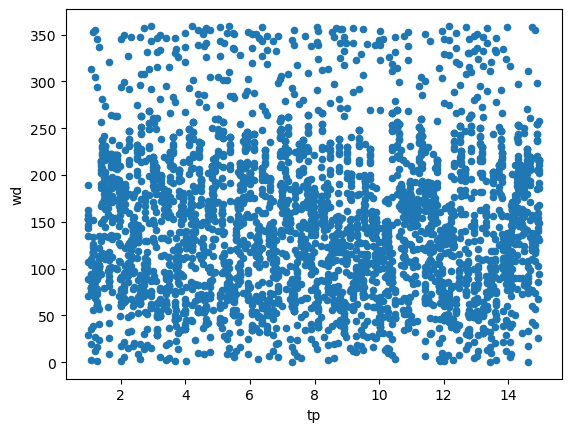

In [3]:
cases_df.plot.scatter(x="tp", y="wd")

In [4]:
from bluemath_tk.wrappers.snapwave.snapwave_wrapper import SnapWaveModelWrapper

snapwave_wrapper = SnapWaveModelWrapper(
    templates_dir="templates-metamodel",
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={},
    output_dir="SnapWave_CASES_METAMODEL",
    aoi_file="inputs/AoI_Polygons/AoI_NorthCarolina.shp",
    goals_config=GOALS,
)
snapwave_wrapper

2026-06-16 10:56:08,016 - SnapWaveModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-06-16 10:56:08,016 - SnapWaveModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-06-16 10:56:08,017 - SnapWaveModelWrapper - WARNING - Parameter wd is not in the default_parameters
2026-06-16 10:56:08,017 - SnapWaveModelWrapper - WARNING - Parameter ds is not in the default_parameters
2026-06-16 10:56:08,018 - SnapWaveModelWrapper - WARNING - Parameter zs is not in the default_parameters


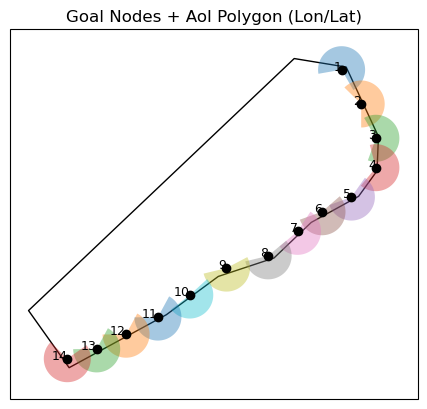

In [5]:
snapwave_wrapper.plot_configuration()

In [5]:
snapwave_wrapper.load_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [6]:
# snapwave_wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [7]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    3500
Name: count, dtype: int64

In [8]:
result_msg = snapwave_wrapper.postprocess_cases()
result_msg

'Olrait!'